# Simulação Computacional do Escoamento Bidimensional de Gotas em Microcanais via BEM (`Stokes Drop 2D`)
## Guia Didático Passo a Passo: Da Geração de Malha Quadrática (`Create_Mesh_2D`) ao Solver Transiente em Fortran 90 (`Processor`) e Pós-Processamento Gráfico

Este Jupyter Notebook apresenta o fluxo completo (**pipeline**) para modelagem geométrica e geração de malha de elementos de contorno quadráticos com **`Create_Mesh_2D`**, compilação e execução do solver transiente em Fortran 90 **`Processor` (`Gota.exe`)**, e pós-processamento numérico e gráfico dos resultados.

Este notebook é **multiplataforma** e foi projetado para executar tanto **localmente (Windows / Linux / macOS)** quanto no **Google Colab (Ubuntu Linux)**.

---
### Referências Acadêmicas no Repositório:
> 1. **Trabalho de Graduação (UnB, 2016)** — **Lucas Hildebrand Pires da Cunha** (Orientador: Prof. Éder Lima de Albuquerque, PhD),  
>    *Aplicação do Método dos Elementos de Contorno ao Escoamento de Gotas em Canais Convergentes.*  
>    Arquivo no repositório: `Projeto_Graduacao.pdf`
> 2. **Artigo Científico (*International Journal of Multiphase Flow* 103, 2018, pp. 141–150)** — **L.H.P. Cunha, I.R. Siqueira, E.L. Albuquerque, T.F. Oliveira**,  
>    *Flow of emulsion drops through a constricted microcapillary channel.*  
>    Arquivo no repositório: `1-s2.0-S0301932217304895-main.pdf`
> 3. **Protótipo Preliminar em MATLAB (Fev/2016)**: `FluidosDeStokes - 20160220/FluidoStokes.m` e manual de entrada `Manual.txt`.

### Arquitetura do Framework em Fortran 90 (4 Etapas):
1. **Definição Geométrica e Parâmetros Adimensionais (`Create_Mesh_2D/dad_*.txt` + `file_name.dat`)**:
   - O contorno externo do microcanal (vértices e segmentos retos ou circulares) e as gotas iniciais são descritos em arquivos `.txt` parametrizados pela razão de viscosidade $\lambda = \mu_d / \mu$, número capilar $\text{Ca} = \mu V / \sigma$ e razão de confinamento $a/H = 2R/H$.
2. **Pré-Processamento e Discretização com Elementos Quadráticos Contínuos (`Create_Mesh_2D/*.f90` $\to$ `Mesh.exe`)**:
   - Gera elementos quadráticos isoparamétricos de 3 nós ($N_{\text{nós}} = 2 N_{\text{elem}}$), impõe perfil parabólico de Poiseuille desenvolvido na entrada (`bc = 2`), paredes impermeáveis com condição de não-deslizamento (`bc = 0`), saída livre de tração (`bc = 1`) e interface livre na gota (`conn(:,5) = 1`), exportando `output.txt`, `wall_contour.plt` e `drop_contour.plt`.
3. **Solver Transiente BEM 2D (`Processor/*.f90` $\to$ `Gota.exe`)**:
   - Monta as matrizes integrais de contorno $[H]$, $[G]$ e $[B]$ para o escoamento de Stokes ($\text{Re} = 0$) com **quadratura de Gauss-Legendre** ($N_{\text{pgr}} = 6$) para integrais regulares e **quadratura logarítmica de Gauss** ($N_{\text{pgs}} = 10$) com subtração de singularidade para integrais logarítmicas singulares.
   - Calcula os blocos diagonais de $[H]$ indiretamente por movimento de corpo rígido, resolve o sistema linear denso $[A]\{x\} = \{b\}$ via **Gradientes Biconjugados (BiCG)** em precisão dupla (`Tol = 1e-8`), avança a interface com esquema **preditor-corretor de 2ª ordem** e aplica duas passagens da **realocação nodal de Wrobel et al. (2009)** por passo de tempo.
4. **Pós-Processamento e Visualização (`pressure.plt`, `flow_error.plt`, `area_error.plt`, `drop_t=*.plt`)**:
   - Monitora a diferença de pressão motriz $\Delta P(t) = P_{\text{in}} - P_{\text{out}}$, o erro relativo de conservação de vazão na saída $e_Q(t)$ e o erro relativo de conservação da área da gota $e_A(t)$ via integração de Simpson e Teorema da Divergência.

## 0. Preparação do Ambiente (Google Colab e Ambiente Local)

Esta célula detecta automaticamente o ambiente de execução:
- **No Google Colab (Linux)**: instala o compilador `gfortran` e verifica os pacotes Python necessários.
- **No Ambiente Local (Windows / Linux / macOS)**: verifica e instala eventuais pacotes Python ausentes (`numpy`, `matplotlib`).

In [1]:
import os
import sys
import subprocess
import importlib

# 1. Detecção do Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("[*] Ambiente Google Colab detectado!")
    print("[*] Instalando compilador gfortran no Linux...")
    try:
        subprocess.run(
            "apt-get update -qq && apt-get install -y -qq gfortran",
            shell=True, check=True
        )
        print("[+] Compilador gfortran instalado com sucesso no Colab!")
    except Exception as e:
        print(f"[!] Aviso ao instalar pacotes apt: {e}")

# 2. Verificação de pacotes Python necessários
required_packages = ['numpy', 'matplotlib']

missing_packages = []
for pkg in required_packages:
    try:
        importlib.import_module(pkg)
    except ImportError:
        missing_packages.append(pkg)

if missing_packages:
    print(f"[*] Instalando pacotes Python ausentes ({missing_packages})...")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing_packages])
    importlib.invalidate_caches()
    print("[+] Pacotes Python instalados com sucesso!")
else:
    print(f"[+] Todos os pacotes necessários ({required_packages}) já estão disponíveis.")

[+] Todos os pacotes necessários (['numpy', 'matplotlib']) já estão disponíveis.


## 1. Configuração do Ambiente e Inspeção dos Casos de Simulação

Configuramos o `PATH` do sistema para que o compilador Fortran (`gfortran` no Windows via MSYS2 UCRT64) esteja acessível na sessão e inspecionamos os diretórios e casos de validação disponíveis em `Create_Mesh_2D/`:
- **`dad_1.txt`**: Canal plano reto ($L = 10H$, $H = 1$) com 1 gota ($a/H = 0,50$, $\lambda = 1,0$, $\text{Ca} = 0,1$);
- **`dad_2.txt`**: Microcapilar plano com constrição ($L = 3H$, razão de contração $H/h = 2$) e 1 gota confinada ($a/H = 0,60$, $\lambda = 10,0$, $\text{Ca} = 1,0$);
- **`dad_3.txt`**: Microcapilar plano longo com constrição severa ($L = 6H$, razão de contração $H/h = 4$, geometria do artigo *Int. J. Multiphase Flow* 2018) e 1 gota ($a/H = 0,30$, $\lambda = 10,0$, $\text{Ca} = 1,0$).

In [2]:
import shutil
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

# No Windows, adiciona MinGW-w64 (MSYS2 UCRT64) ao início do PATH para o gfortran
if os.name == 'nt':
    ucrt64_bin = "C:/msys64/ucrt64/bin"
    if os.path.exists(ucrt64_bin) and ucrt64_bin not in os.environ["PATH"]:
        os.environ["PATH"] = ucrt64_bin + os.pathsep + os.environ["PATH"]

ROOT_DIR = Path(os.getcwd()).resolve()
MESH_DIR = ROOT_DIR / "Create_Mesh_2D"
PROC_DIR = ROOT_DIR / "Processor"
EXAMPLES_DIR = ROOT_DIR / "examples"
EXAMPLES_DIR.mkdir(parents=True, exist_ok=True)

def summarize_dad_file(path: Path) -> dict:
    tokens = []
    for line in path.read_text(encoding="utf-8", errors="ignore").splitlines():
        clean = line.split("!")[0].strip()
        if clean:
            tokens.append(clean.split())
    npts, nseg, ndrop = map(int, tokens[0][:3])
    dt, max_pos, max_it = float(tokens[1][0]), float(tokens[1][1]), int(tokens[1][2])
    pts = np.array([[float(x) for x in tokens[2 + i][:3]] for i in range(npts)])
    disc_idx = 2 + npts + 2 * nseg
    disc = np.array([[int(float(x)) for x in tokens[disc_idx + i][:2]] for i in range(nseg)])
    drop_nele = int(float(tokens[disc_idx + nseg][0]))
    lam = float(tokens[disc_idx + nseg + 1][0])
    ca = float(tokens[disc_idx + nseg + 2][0])
    dgeom = [float(x) for x in tokens[disc_idx + nseg + 3][:4]]
    H = pts[-1, 2] - pts[0, 2]
    nele = int(disc[:, 1].sum()) + ndrop * drop_nele
    return {
        "case": path.stem, "npts": npts, "nseg": nseg, "ndrop": ndrop,
        "nele": nele, "nnode": 2 * nele, "drop_nele": drop_nele,
        "dt": dt, "max_pos": max_pos, "max_it": max_it,
        "lambda": lam, "Ca": ca, "aH": 2.0 * dgeom[3] / H, "R": dgeom[3]
    }

print("Ambiente configurado com sucesso!")
print(f"Sistema Operacional : {sys.platform} ({os.name})")
print(f"Diretório do projeto: {ROOT_DIR}\n")
print("Casos de entrada disponíveis em Create_Mesh_2D/:")
for fname in ["dad_1.txt", "dad_2.txt", "dad_3.txt"]:
    info = summarize_dad_file(MESH_DIR / fname)
    print(
        f"  [{info['case']}] {info['nele']:4d} elem ({info['nnode']:4d} nós) | "
        f"gota: {info['drop_nele']} elem, R={info['R']:.2f} (a/H={info['aH']:.2f}) | "
        f"lambda={info['lambda']:.1f}, Ca={info['Ca']:.2f} | dt={info['dt']}, max_it={info['max_it']}"
    )

Ambiente configurado com sucesso!
Sistema Operacional : win32 (nt)
Diretório do projeto: C:\Users\Adm\OneDrive - unb.br\Antigravity\Drop

Casos de entrada disponíveis em Create_Mesh_2D/:
  [dad_1]  470 elem ( 940 nós) | gota: 30 elem, R=0.25 (a/H=0.50) | lambda=1.0, Ca=0.10 | dt=0.001, max_it=5000
  [dad_2]  220 elem ( 440 nós) | gota: 40 elem, R=0.30 (a/H=0.60) | lambda=10.0, Ca=1.00 | dt=0.001, max_it=8000
  [dad_3]  820 elem (1640 nós) | gota: 40 elem, R=0.15 (a/H=0.30) | lambda=10.0, Ca=1.00 | dt=0.0025, max_it=5000


## 2. Como Modelar a Geometria do Canal, Condições de Contorno e Gotas (`Create_Mesh_2D/dad_*.txt`)

No Método dos Elementos de Contorno aplicado a escoamentos de Stokes ($\text{Re} = 0$), apenas o **contorno 1D do canal** e a **interface fechada da gota** precisam ser discretizados:

### Estrutura do Arquivo de Entrada (`dad_*.txt`, lido por `readmesh.f90`):
1. **Cabeçalho e contadores gerais**: linha de comentário inicial seguida por `npts  nseg  ndrop` (número de vértices do contorno externo, número de segmentos e número de gotas);
2. **Parâmetros temporais e de parada**: linha de comentário seguida por `dt  max_pos  max_it` (passo de tempo $\Delta t$, posição máxima $x$ do primeiro nó da gota e número máximo de iterações);
3. **Coordenadas dos vértices (`npts` linhas)**: `id  x  y` percorrendo o contorno externo no **sentido anti-horário** (vetor normal unitário apontando para fora do domínio);
4. **Topologia dos segmentos (`nseg` linhas)**: `id  pt_ini  pt_fim  raio  flag_contorno`, onde:
   - `raio = 0.0` indica segmento reto (`> 0` arco com centro à esquerda, `< 0` arco com centro à direita);
   - `flag_contorno = 0.0` (parede), `-1.0` (seção de entrada / *inlet*) ou `-2.0` (seção de saída / *outlet*);
5. **Condições de contorno por segmento (`nseg` linhas)**: `id  tipo_x  valor_x  tipo_y  valor_y`, onde:
   - `tipo = 0.0`: velocidade prescrita ($u_x$ ou $u_y$);
   - `tipo = 1.0`: tração superficial prescrita ($t_x$ ou $t_y$);
   - `tipo = 2.0`: **perfil parabólico de Poiseuille desenvolvido** normal ao segmento reto, com velocidade média $V_m$ informada na 3ª coluna (`valor_x`):
     $$u_n(d) = \frac{3}{2} V_m \left[1 - \left(\frac{2d}{H}\right)^2\right]$$
6. **Discretização e propriedades físicas**: número de elementos quadráticos em cada segmento (`id  nelem`), elementos por gota (`drop_nele`), razão de viscosidade $\lambda$, número capilar $\text{Ca}$ e posição inicial de cada gota (`id  x_c  y_c  raio`).

Abaixo inspecionamos os arquivos `dad_1.txt` (canal reto) e `dad_2.txt` (canal constrito):

In [3]:
dad1_text = (MESH_DIR / "dad_1.txt").read_text(encoding="utf-8")
print("=" * 78)
print(" Arquivo: Create_Mesh_2D/dad_1.txt (Canal Plano Reto - 1 Gota)")
print("=" * 78)
print(dad1_text)

dad2_text = (MESH_DIR / "dad_2.txt").read_text(encoding="utf-8")
print("=" * 78)
print(" Arquivo: Create_Mesh_2D/dad_2.txt (Microcapilar Constrito H/h = 2 - 1 Gota)")
print("=" * 78)
print(dad2_text)

 Arquivo: Create_Mesh_2D/dad_1.txt (Canal Plano Reto - 1 Gota)
!OUTER CONTOUR DATA
4	4  	1	!n# of points !n# os segments !n# of drops 

!SIMULATION PARAMETERS
0.001	9.5	5000	!time step   !final position of the first node !max number of iterations

1	0	0 !Defining the points 
2	10	0 !(i# point, x_i, y_i)
3 	10 	1
4 	0 	1

1.0 	1.0 	2.0 	 0.0	0.0 !conect the points to create the contour !(i# seg, pt1, pt2, segment shape, inlet(-1.0) or outlet(-2.0)
2.0 	2.0 	3.0	 0.0   -2.0 !(seg shape == 0 -> straight line, seg shape /= 0 -> radio of the circle segment)
3.0 	3.0 	4.0	 0.0 	0.0 !(seg shape > 0 -> circle center on the left, seg shape< 0 -> circle center on the right)
4.0 	4.0 	1.0 	 0.0   -1.0
        
1.0 	0.0	0.0 	0.0 	0.0	!boundary condition on the segments
2.0 	1.0 	0.0 	1.0 	0.0	!(i# seg, bc type on x direct, value of the bc, bc type on y dirct, value of the bc)
3.0 	0.0 	0.0 	0.0 	0.0 	!(bc type = 0 --> velocity ; bc type = 1 --> tension ; bc type = 3 --> drop)
4.0 	2.0 	1.0 	0.0 	0

## 3. Compilação e Execução do Gerador de Malha 2D (`Create_Mesh_2D/Mesh.exe`)

O pré-processador em `Create_Mesh_2D/` é composto por 15 arquivos Fortran 90:
- `variables.f90` (módulo `global`) deve ser compilado **primeiro**;
- `getfilename.f90` lê o nome do caso ativo em `file_name.dat` (sem extensão `.txt`);
- `readmesh.f90`, `alloc_memory1.f90` e `alloc_memory2.f90` leem o arquivo `<caso>.txt` e alocam as estruturas;
- `meshdisc.f90`, `create_nodes_conn.f90`, `calc_arc.f90`, `circle_center.f90`, `calc_maxdim.f90` e `max_dimension.f90` geram as coordenadas nodais `xnode` e a matriz de conectividade quadrática `conn` (3 nós por elemento);
- `format_bc.f90` avalia as condições de contorno nos 3 nós de cada elemento;
- `output_file.f90` e `tecplot_contour.f90` gravam `output.txt`, `wall_contour.plt` e `drop_contour.plt`.

Abaixo compilamos `Mesh.exe`, executamos a geração da malha para `dad_2` (passando `\n` via `input` para encerrar o comando `PAUSE` do Fortran) e plotamos as malhas quadráticas e condições de contorno dos casos **`dad_2`** ($440$ nós) e **`dad_3`** ($1640$ nós):

[*] Compilando Create_Mesh_2D: gfortran -O2 -static -ffree-line-length-512 variables.f90 ... -o Mesh.exe
[OK] Compilação de 'Mesh.exe' concluída com código 0!
[OK] 'Mesh.exe' executado para o caso 'dad_2' -> Create_Mesh_2D/output.txt gerado.
  -> Malha dad_2: 220 elementos, 440 nós (gota: nós 361 a 440)
  -> Malha dad_3: 820 elementos, 1640 nós (gota: nós 1561 a 1640)

Visualização das malhas quadráticas e condições de contorno:


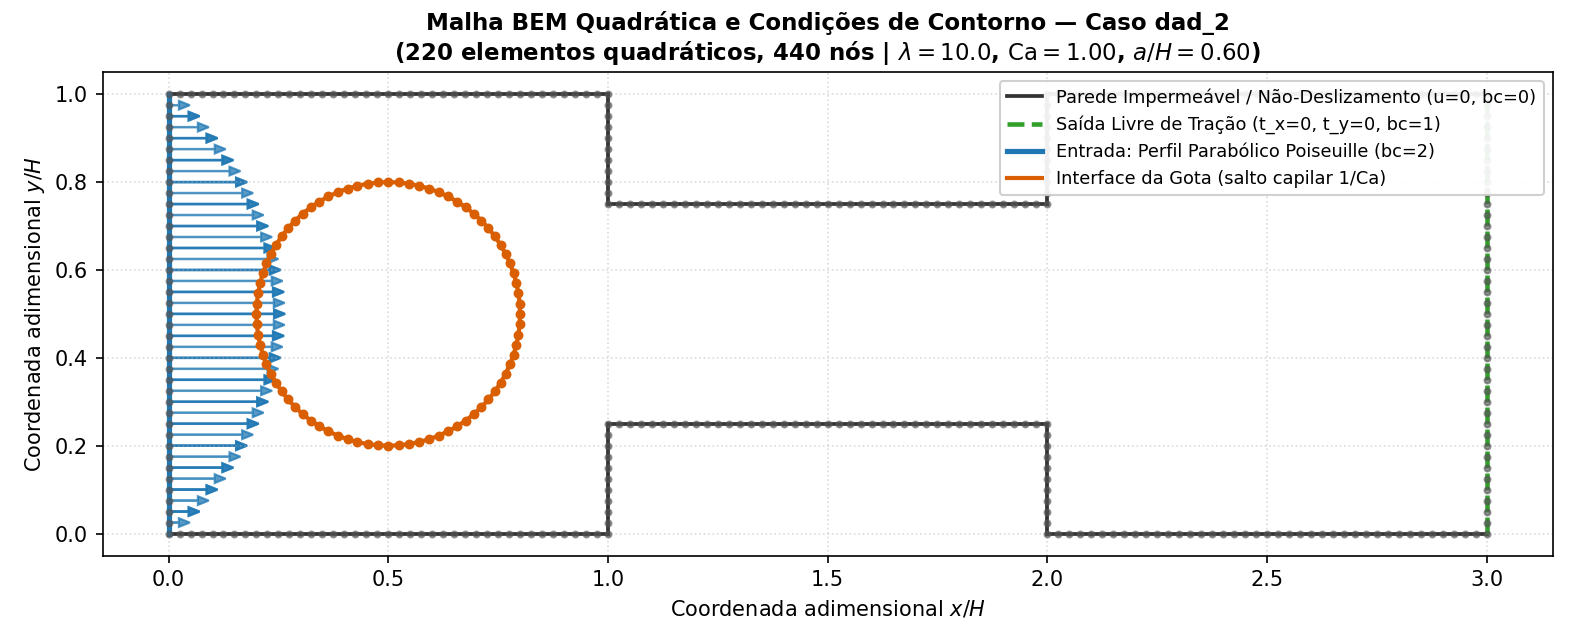

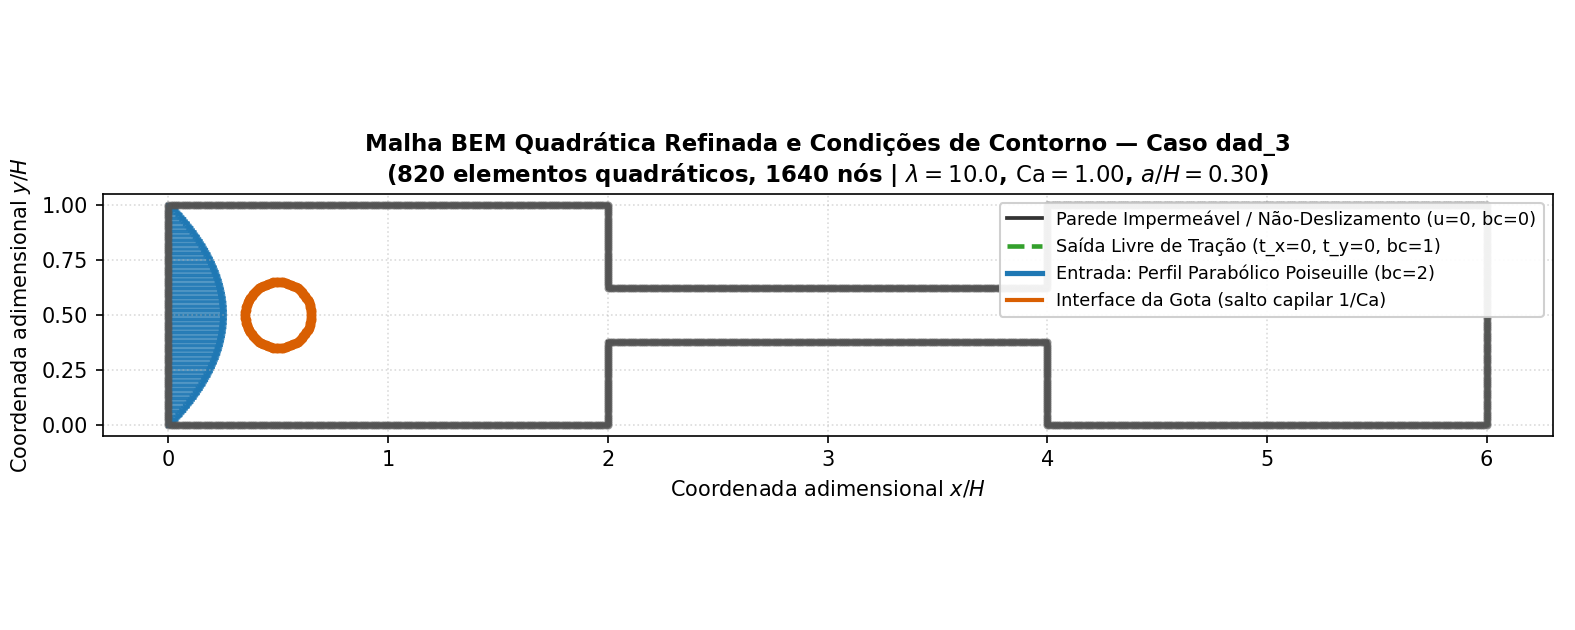

In [4]:
mesh_sources = [
    "variables.f90", "alloc_memory1.f90", "alloc_memory2.f90", "calc_arc.f90",
    "calc_maxdim.f90", "circle_center.f90", "create_nodes_conn.f90", "format_bc.f90",
    "getfilename.f90", "max_dimension.f90", "meshdisc.f90", "output_file.f90",
    "readmesh.f90", "tecplot_contour.f90", "Mesh.f90"
]
mesh_exe = MESH_DIR / ("Mesh.exe" if os.name == "nt" else "Mesh")
static_flags = ["-static"] if os.name == "nt" else []

# Remove artefatos .mod/.o antigos antes de compilar
for old_f in list(MESH_DIR.glob("*.mod")) + list(MESH_DIR.glob("*.o")):
    old_f.unlink()

cmd_compile_mesh = ["gfortran", "-O2", *static_flags, "-ffree-line-length-512", *mesh_sources, "-o", str(mesh_exe)]
print("[*] Compilando Create_Mesh_2D:", " ".join(cmd_compile_mesh[:5]), "... -o", mesh_exe.name)
res_mesh_build = subprocess.run(cmd_compile_mesh, cwd=str(MESH_DIR), capture_output=True, text=True)
if res_mesh_build.returncode != 0:
    raise RuntimeError(res_mesh_build.stderr)
print(f"[OK] Compilação de '{mesh_exe.name}' concluída com código 0!")

# Seleciona 'dad_2' em file_name.dat e executa Mesh.exe
(MESH_DIR / "file_name.dat").write_text("dad_2\n", encoding="utf-8")
res_mesh_run = subprocess.run([str(mesh_exe)], cwd=str(MESH_DIR), input="\n", capture_output=True, text=True, check=True)
print(f"[OK] '{mesh_exe.name}' executado para o caso 'dad_2' -> Create_Mesh_2D/output.txt gerado.")

def parse_output_txt(path: Path) -> dict:
    lines = path.read_text(encoding="utf-8", errors="ignore").splitlines()
    nnode, nele, ndrop = map(int, lines[0].split("#")[0].split()[:3])
    s2 = lines[2].split("#")[0].split()
    dt, max_pos, max_it = float(s2[0]), float(s2[1]), int(s2[2])
    xnode = np.array([[float(x) for x in lines[6 + i].split()[:3]] for i in range(nnode)])
    c0 = 6 + nnode + 3
    conn = np.array([[int(x) for x in lines[c0 + i].split()[:5]] for i in range(nele)], dtype=int)
    b0 = c0 + nele + 3
    bc = np.array([[float(x) for x in lines[b0 + i].split()[:13]] for i in range(nele)])
    d0 = b0 + nele + 3
    drop_nodes = np.array([[int(x) for x in lines[d0 + i].split()[:3]] for i in range(ndrop)], dtype=int)
    p0 = lines[d0 + ndrop + 3].split()
    return {
        "nnode": nnode, "nele": nele, "ndrop": ndrop, "dt": dt, "max_pos": max_pos, "max_it": max_it,
        "xnode": xnode, "conn": conn, "bc": bc, "drop_nodes": drop_nodes,
        "lambda": float(p0[0]), "Ca": float(p0[1]), "aH": float(p0[2])
    }

mesh_dad2 = parse_output_txt(MESH_DIR / "output.txt")
mesh_dad3 = parse_output_txt(PROC_DIR / "output.txt")
print(f"  -> Malha dad_2: {mesh_dad2['nele']} elementos, {mesh_dad2['nnode']} nós (gota: nós {mesh_dad2['drop_nodes'][0,1]} a {mesh_dad2['drop_nodes'][0,2]})")
print(f"  -> Malha dad_3: {mesh_dad3['nele']} elementos, {mesh_dad3['nnode']} nós (gota: nós {mesh_dad3['drop_nodes'][0,1]} a {mesh_dad3['drop_nodes'][0,2]})")

def plot_mesh_and_bc(mesh_data, title_str, out_png: Path):
    xnode, conn, bc = mesh_data["xnode"], mesh_data["conn"], mesh_data["bc"]
    fig, ax = plt.subplots(figsize=(10.5, 4.2), dpi=150)
    labels_done = set()
    for e in range(mesh_data["nele"]):
        n1, n2, n3, etype = conn[e, 1] - 1, conn[e, 2] - 1, conn[e, 3] - 1, conn[e, 4]
        xs, ys = [xnode[n1, 1], xnode[n2, 1], xnode[n3, 1]], [xnode[n1, 2], xnode[n2, 2], xnode[n3, 2]]
        if etype == 1:
            lbl = "Interface da Gota (salto capilar 1/Ca)" if 1 not in labels_done else ""
            ax.plot(xs, ys, "-", color="#d95f02", lw=2.0, label=lbl)
        elif etype == -1:
            lbl = "Entrada: Perfil Parabólico Poiseuille (bc=2)" if -1 not in labels_done else ""
            ax.plot(xs, ys, "-", color="#1f78b4", lw=2.5, label=lbl)
            for ni, vx, vy in [(n1, bc[e, 2], bc[e, 4]), (n2, bc[e, 6], bc[e, 8]), (n3, bc[e, 10], bc[e, 12])]:
                if abs(vx) > 1e-4 or abs(vy) > 1e-4:
                    ax.arrow(xnode[ni, 1], xnode[ni, 2], 0.16 * vx, 0.16 * vy,
                             head_width=0.02, head_length=0.025, fc="#1f78b4", ec="#1f78b4", alpha=0.75)
        elif etype == -2:
            lbl = "Saída Livre de Tração (t_x=0, t_y=0, bc=1)" if -2 not in labels_done else ""
            ax.plot(xs, ys, "--", color="#33a02c", lw=2.2, label=lbl)
        else:
            lbl = "Parede Impermeável / Não-Deslizamento (u=0, bc=0)" if 0 not in labels_done else ""
            ax.plot(xs, ys, "-", color="#333333", lw=1.8, label=lbl)
        labels_done.add(etype)
    first_drop_nd = mesh_data["drop_nodes"][0, 1] - 1
    ax.scatter(xnode[:first_drop_nd, 1], xnode[:first_drop_nd, 2], s=8, color="#555555", alpha=0.6, zorder=3)
    ax.scatter(xnode[first_drop_nd:, 1], xnode[first_drop_nd:, 2], s=14, color="#d95f02", zorder=4)
    ax.set_title(
        f"{title_str}\n({mesh_data['nele']} elementos quadráticos, {mesh_data['nnode']} nós | "
        f"$\\lambda={mesh_data['lambda']:.1f}$, $\\mathrm{{Ca}}={mesh_data['Ca']:.2f}$, $a/H={mesh_data['aH']:.2f}$)",
        fontsize=11, fontweight="bold"
    )
    ax.set_xlabel("Coordenada adimensional $x / H$")
    ax.set_ylabel("Coordenada adimensional $y / H$")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, linestyle=":", alpha=0.45)
    ax.legend(loc="upper right", fontsize=8.5, framealpha=0.92)
    fig.tight_layout()
    fig.savefig(out_png, dpi=150)
    plt.close(fig)

plot_mesh_and_bc(mesh_dad2, "Malha BEM Quadrática e Condições de Contorno — Caso dad_2", EXAMPLES_DIR / "dad_2_mesh_bc.png")
plot_mesh_and_bc(mesh_dad3, "Malha BEM Quadrática Refinada e Condições de Contorno — Caso dad_3", EXAMPLES_DIR / "dad_3_mesh_bc.png")

print("\nVisualização das malhas quadráticas e condições de contorno:")
display(Image(filename=str(EXAMPLES_DIR / "dad_2_mesh_bc.png"), width=740))
display(Image(filename=str(EXAMPLES_DIR / "dad_3_mesh_bc.png"), width=740))

## 4. Inspecionando o Arquivo `output.txt` Gerado para o Solver BEM

O arquivo `output.txt` faz a ponte entre o gerador de malha (`Create_Mesh_2D`) e o solver transiente (`Processor`). Ele armazena:
1. **`nnode, nele, ndrop`** e **`dt, max_pos, max_it`**;
2. **`NODES COORDINATES`**: índice global do nó (`1 .. nnode`) e coordenadas $(x, y)$;
3. **`CONNECTIVITY`**: `elem_id  no_1  no_2  no_3  tipo_contorno` (`0` = parede, `-1` = entrada, `-2` = saída, `1` = interface da gota);
4. **`ELEM BOUNDARY CONDITIONS`**: `elem_id` seguido por 12 valores `(tipo_x, val_x, tipo_y, val_y)` para os 3 nós do elemento quadrático;
5. **`DROPS FIRST AND LAST NODES`** e **`DROPS PROPERTIES`** ($\lambda, \text{Ca}, a/H$).

In [5]:
with open(MESH_DIR / "output.txt", "r", encoding="utf-8") as f:
    out_lines = f.readlines()

print("=== Cabeçalho e Primeiros Nós de Create_Mesh_2D/output.txt (Caso dad_2) ===")
print("".join(out_lines[:18]))
print("=== Conectividade e Condições de Contorno (Trecho Final de output.txt) ===")
print("".join(out_lines[-22:]))

=== Cabeçalho e Primeiros Nós de Create_Mesh_2D/output.txt (Caso dad_2) ===
       440       220         1        #number of nodes, elements and drops

         0.0010000         3.8000000      8000   #time step, max drop position and max iteration

 NODES COORDINATES (i# node, x, y)

         1.0000000         0.0000000         0.0000000
         2.0000000         0.0250000         0.0000000
         3.0000000         0.0500000         0.0000000
         4.0000000         0.0750000         0.0000000
         5.0000000         0.1000000         0.0000000
         6.0000000         0.1250000         0.0000000
         7.0000000         0.1500000         0.0000000
         8.0000000         0.1750000         0.0000000
         9.0000000         0.2000000         0.0000000
        10.0000000         0.2250000         0.0000000
        11.0000000         0.2500000         0.0000000
        12.0000000         0.2750000         0.0000000

=== Conectividade e Condições de Contorno (Trecho Fin

## 5. Compilação do Solver Transiente BEM 2D (`Processor/Gota.exe`)

O solver em `Processor/` resolve a equação integral de contorno para escoamento bifásico de Stokes ($\text{Re} = 0$):
$$c_{ij}(\mathbf{x}_0) u_j(\mathbf{x}_0) + \int_{\Gamma_w} K_{ij}(\mathbf{x}_0, \mathbf{x}) n_k(\mathbf{x}) u_j(\mathbf{x})\,\mathrm{d}\Gamma + \frac{a}{H}(1 - \lambda)\int_{\Gamma_d} K_{ij}(\mathbf{x}_0, \mathbf{x}) n_k(\mathbf{x}) u_j(\mathbf{x})\,\mathrm{d}\Gamma = \int_{\Gamma_w} J_{ij}(\mathbf{x}_0, \mathbf{x}) t_j(\mathbf{x})\,\mathrm{d}\Gamma - \frac{1}{\text{Ca}}\int_{\Gamma_d} J_{ij}(\mathbf{x}_0, \mathbf{x}) \kappa(\mathbf{x}) n_j(\mathbf{x})\,\mathrm{d}\Gamma$$

### Organização Modular do Solver (`Processor/`):
1. `variables.f90` (`global`) e `variables_build_HGB.f90` (`var_build_HGB`) — Módulos globais (compilados primeiro);
2. `read_input.f90`, `alloc_memory.f90`, `alloc_memory_build_HGB.f90`, `first_drop_elem.f90` — Leitura de `output.txt` e alocação dinâmica;
3. `Gauss_Legendre.f90`, `Gauss_Logaritimic.f90`, `transform_eta_qsi.f90`, `shape_functions.f90`, `shape_functions_sing.f90` — Quadraturas regular ($N_{\text{pgr}}=6$) e logarítmica ($N_{\text{pgs}}=10$) e funções de forma quadráticas;
4. `geometric_parameters.f90`, `calc_radius.f90`, `calc_curv_nodes.f90`, `calc_circle_curv.f90`, `curv_sign.f90`, `calc_drop_area.f90` — Vetores normais, tangentes, jacobiano, curvatura local $\kappa$ e área da gota;
5. `building_HGB_sing.f90`, `regular_integral.f90`, `sing_integral.f90`, `sing_reg_integral.f90`, `mat_prod_2x2_2x6.f90` — Montagem das matrizes $[H]$, $[G]$ e $[B]$ com decomposição singular + regular;
6. `apply_bc2.f90`, `prod_Axb.f90`, `Conj_grad.f90`, `reorganize.f90` — Aplicação das condições de contorno e solução do sistema $[A]\{x\} = \{b\}$ via **BiCG** (`Tol = 1e-8`);
7. `evolution_euler.f90`, `evolution_euler_implicit.f90`, `nodes_relocation.f90` — Esquema preditor-corretor de 2ª ordem e realocação nodal de Wrobel et al. (2009);
8. `flow_error.f90`, `driver_pressure.f90`, `tecplot_contour.f90`, `Processing.f90` — Cálculo de $\Delta P(t)$, erro de vazão $e_Q(t)$, erro de área $e_A(t)$ e exportação `.plt`.

> **Flags críticas de compilação**:
> - `-fopenmp`: paraleliza a montagem das matrizes `H`, `G` e `B` (`building_HGB_sing.f90`), o produto matriz-vetor (`prod_Axb.f90`) e o `dgemm` usado na fatoração LU;
> - `-llapack -lblas`: vincula a rotina direta `dgesv` do LAPACK (`lapack_solver.f90`) para resolução do sistema linear;
> - `-fdefault-real-8 -fdefault-double-8`: promove variáveis `real` para dupla precisão (64 bits) mantendo `double precision` (`0.0d0`) também em 64 bits compatível com a ABI do LAPACK;
> - `-Wl,--stack,536870912` (no Windows): reserva 512 MB de *stack* para acomodar arrays automáticos como `matB(2*nnode, 6*nele)` em `apply_bc2.f90`.

In [6]:
proc_sources = [
    "variables.f90", "variables_build_HGB.f90", "alloc_memory.f90", "alloc_memory_build_HGB.f90",
    "apply_bc.f90", "apply_bc2.f90", "building_HGB.f90", "building_HGB_sing.f90",
    "calc_circle_curv.f90", "calc_curv_nodes.f90", "calc_drop_area.f90", "calc_radius.f90",
    "Conj_grad.f90", "lapack_solver.f90", "curv_sign.f90", "driver_pressure.f90", "evolution_euler.f90",
    "evolution_euler_implicit.f90", "first_drop_elem.f90", "flow_error.f90", "gauss_elimination.f90",
    "Gauss_Legendre.f90", "Gauss_Logaritimic.f90", "geometric_parameters.f90", "mat_prod_2x2_2x6.f90",
    "nodes_relocation.f90", "prod_Axb.f90", "read_input.f90", "regular_integral.f90", "reorganize.f90",
    "shape_functions.f90", "shape_functions_sing.f90", "sing_integral.f90", "sing_reg_integral.f90",
    "tecplot_contour.f90", "transform_eta_qsi.f90", "write_HGB.f90", "write_matA.f90", "Processing.f90"
]
gota_exe = PROC_DIR / ("Gota.exe" if os.name == "nt" else "Gota")
platform_flags = ["-static", "-Wl,--stack,536870912"] if os.name == "nt" else []

for old_f in list(PROC_DIR.glob("*.mod")) + list(PROC_DIR.glob("*.o")):
    old_f.unlink()

cmd_compile_proc = [
    "gfortran", "-O3", "-march=native", "-fopenmp", "-fdefault-real-8", "-fdefault-double-8", "-ffree-line-length-512",
    *platform_flags, *proc_sources, "-llapack", "-lblas", "-o", str(gota_exe)
]
print("[*] Compilando Processor:", " ".join(cmd_compile_proc[:9]), "... -llapack -lblas -o", gota_exe.name)
res_proc_build = subprocess.run(cmd_compile_proc, cwd=str(PROC_DIR), capture_output=True, text=True)
if res_proc_build.returncode != 0:
    raise RuntimeError(res_proc_build.stderr)
print(f"[OK] Compilação de '{gota_exe.name}' concluída com código 0 ({gota_exe.stat().st_size:,} bytes)!")

[*] Compilando Processor: gfortran -O3 -march=native -fopenmp -fdefault-real-8 -fdefault-double-8 -ffree-line-length-512 -static -Wl,--stack,536870912 ... -llapack -lblas -o Gota.exe
[OK] Compilação de 'Gota.exe' concluída com código 0 (1,136,672 bytes)!


## 6. Execução do Solver BEM (`Processor/Gota.exe`)

Abaixo demonstramos a execução do solver em duas configurações complementares:
1. **Execução rápida ao vivo (`results/dad_2_demo`)**: roda `30` passos de tempo ($\Delta t = 0,001$) para a malha `dad_2` ($440$ nós, $220$ elementos, $a/H = 0,60$, $\lambda = 10$, $\text{Ca} = 1,0$) em ~4,1 segundos (com OpenMP + LAPACK `dgesv`);
2. **Simulação de alta resolução do microcapilar constrito (`Processor/`)**: `50` passos de tempo ($\Delta t = 0,0025$, $t \in [0,0025;\; 0,1250]$) para a malha refinada `dad_3` ($1640$ nós, $820$ elementos, razão de contração $H/h = 4$, $a/H = 0,30$, $\lambda = 10$, $\text{Ca} = 1,0$).

In [7]:
RESULTS_DIR = ROOT_DIR / "results" / "dad_2_demo"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
for old_plt in RESULTS_DIR.glob("*.plt"):
    old_plt.unlink()

# Prepara output.txt de dad_2 com max_it = 30 para demonstração rápida
dad2_lines = (MESH_DIR / "output.txt").read_text(encoding="utf-8").splitlines()
dad2_lines[2] = "         0.0010000         3.8000000        30   #time step, max drop position and max iteration"
(RESULTS_DIR / "output.txt").write_text("\n".join(dad2_lines) + "\n", encoding="utf-8")

t0 = time.perf_counter()
res_run = subprocess.run([str(gota_exe)], cwd=str(RESULTS_DIR), capture_output=True, text=True, check=True)
elapsed = time.perf_counter() - t0

log_lines = res_run.stdout.strip().splitlines()
print("=== Trecho Final do Log de Execução (dad_2 — 30 passos) ===")
print("\n".join(log_lines[-14:]))
print(f"\n[OK] Caso demonstrativo 'dad_2' (440 nós, 30 passos) concluído em {elapsed:.2f} s -> {RESULTS_DIR}")
print(f"[OK] Resultados de alta resolução 'dad_3' (1640 nós, 50 passos) disponíveis em -> {PROC_DIR}")

=== Trecho Final do Log de Execução (dad_2 — 30 passos) ===
          30
 building_HGB_sing (OpenMP)
 apply_bc2
 solve_lapack (dgesv)
 reorganize
 Droplet evolution
 building_HGB_sing (OpenMP)
 apply_bc2
 solve_lapack (dgesv)
 reorganize
 Droplet evolution
 time =   0.13899993896484375     

[OK] Caso demonstrativo 'dad_2' (440 nós, 30 passos) concluído em 4.10 s -> C:\Users\Adm\OneDrive - unb.br\Antigravity\Drop\results\dad_2_demo
[OK] Resultados de alta resolução 'dad_3' (1640 nós, 50 passos) disponíveis em -> C:\Users\Adm\OneDrive - unb.br\Antigravity\Drop\Processor


## 7. Análise dos Resultados Numéricos e Validação com o TCC e o Artigo

O solver grava a cada passo de tempo os arquivos Tecplot `.plt`:
- **`pressure.plt`**: tempo adimensional $t$ e diferença de pressão motriz $\Delta P(t) = P_{\text{in}} - P_{\text{out}}$ integrada pela regra 1/3 de Simpson (`driver_pressure.f90`);
- **`flow_error.plt`**: erro percentual de conservação de massa/vazão entre saída e entrada (`flow_error.f90`):
  $$e_Q(t) = \frac{Q_{\text{out}} - Q_{\text{in}}}{Q_{\text{in}}} \times 100\%$$
- **`area_error.plt`**: erro percentual de conservação da área da gota incompressível (`calc_drop_area.f90` + `tecplot_contour.f90`):
  $$e_A(t) = \frac{A(t) - A_0}{A_0} \times 100\%, \qquad A = \frac{1}{2}\oint_{\Gamma_d} (\mathbf{x}\cdot\mathbf{n})\,\mathrm{d}\Gamma$$
- **`drop_t=XXXXX.plt`** e **`wall_contour.plt`**: coordenadas $(x, y)$ dos nós da interface da gota e das paredes do canal no passo 1 e a cada 10 passos.

Abaixo inspecionamos os valores numéricos obtidos nos dois casos e verificamos os critérios de convergência estabelecidos no TCC (`Projeto_Graduacao.pdf`, Cap. 4: $|e_Q| \lesssim 1,5\%$ para malha refinada $N_e = 7$ e $|e_A| < 0,5\%$):

In [8]:
press_d3 = np.loadtxt(PROC_DIR / "pressure.plt")
flow_d3 = np.loadtxt(PROC_DIR / "flow_error.plt")
area_d3 = np.loadtxt(PROC_DIR / "area_error.plt")
drop_t3 = np.loadtxt(PROC_DIR / "drop_t=    3.plt")
drop_t125 = np.loadtxt(PROC_DIR / "drop_t=  125.plt")

press_d2 = np.loadtxt(RESULTS_DIR / "pressure.plt")
flow_d2 = np.loadtxt(RESULTS_DIR / "flow_error.plt")
area_d2 = np.loadtxt(RESULTS_DIR / "area_error.plt")

print("=" * 78)
print(" 1) Resultados de Alta Resolução: Caso dad_3 (1640 nós, 820 elem, 50 passos)")
print("=" * 78)
print(f"{'Passo':>5s} | {'Tempo t':>10s} | {'Delta P':>14s} | {'Erro Vazão (%)':>15s} | {'Erro Área (%)':>15s}")
print("-" * 70)
for idx in [0, 1, 3, 9, 19, 29, 39, 49]:
    print(f"{idx+1:5d} | {press_d3[idx,0]:10.4f} | {press_d3[idx,1]:14.4f} | {flow_d3[idx,1]:15.6f} | {area_d3[idx,1]:15.7f}")

print(f"\n  -> Máximo |Erro de Área| (dad_3) : {np.max(np.abs(area_d3[:,1])):.6f}% (critério TCC: < 0.50%)")
print(f"  -> Erro de Vazão na saída (dad_3): {np.mean(flow_d3[:,1]):.4f}% (referência TCC Ne=7: ~1.50%)")
print(f"  -> Posição x da gota (dad_3)     : [{drop_t3[:,0].min():.4f}, {drop_t3[:,0].max():.4f}] (t=0.0025) -> [{drop_t125[:,0].min():.4f}, {drop_t125[:,0].max():.4f}] (t=0.1250)")

print("\n" + "=" * 78)
print(" 2) Resultados do Caso Demonstrativo: Caso dad_2 (440 nós, 220 elem, 30 passos)")
print("=" * 78)
print(f"  -> Delta P inicial / final (dad_2): {press_d2[0,1]:.4f} -> {press_d2[-1,1]:.4f}")
print(f"  -> Máximo |Erro de Área| (dad_2)  : {np.max(np.abs(area_d2[:,1])):.6f}% (critério TCC: < 0.50%)")

 1) Resultados de Alta Resolução: Caso dad_3 (1640 nós, 820 elem, 50 passos)
Passo |    Tempo t |        Delta P |  Erro Vazão (%) |   Erro Área (%)
----------------------------------------------------------------------
    1 |     0.0025 |      1698.8345 |       -1.370935 |      -0.0000007
    2 |     0.0050 |      1698.8358 |       -1.370898 |      -0.0008842
    4 |     0.0100 |      1698.8375 |       -1.370870 |      -0.0012205
   10 |     0.0250 |      1698.8414 |       -1.370859 |      -0.0005292
   20 |     0.0500 |      1698.8465 |       -1.370875 |       0.0000671
   30 |     0.0750 |      1698.8509 |       -1.370892 |       0.0001469
   40 |     0.1000 |      1698.8545 |       -1.370907 |       0.0001373
   50 |     0.1250 |      1698.8576 |       -1.370921 |       0.0001095

  -> Máximo |Erro de Área| (dad_3) : 0.001221% (critério TCC: < 0.50%)
  -> Erro de Vazão na saída (dad_3): -1.3709% (referência TCC Ne=7: ~1.50%)
  -> Posição x da gota (dad_3)     : [0.3536, 0.6536] (t

## 8. Pós-Processamento Gráfico: Evolução da Gota, Pressão Motriz e Conservação Numérica

Abaixo exibimos os gráficos gerados a partir dos arquivos `.plt` de saída do solver Fortran:
1. **Figura 1**: Geometria completa do microcapilar constrito ($H/h = 4$) e zoom na translação/deformação dos nós quadráticos da interface da gota (`drop_t=    3.plt` até `drop_t=  125.plt`);
2. **Figura 2**: Evolução temporal da diferença de pressão motriz $\Delta P(t)$ nos canais constritos `dad_3` ($H/h = 4$) e `dad_2` ($H/h = 2$);
3. **Figura 3**: Curvas de erro percentual de conservação de vazão $e_Q(t)$ e conservação da área da gota $e_A(t)$;
4. **Figura 4**: Painel Resumo Integrado 2x2 (*Dashboard*).


=== Figura 1 — Microcapilar Constrito e Evolução dos Perfis da Gota (dad_3) ===


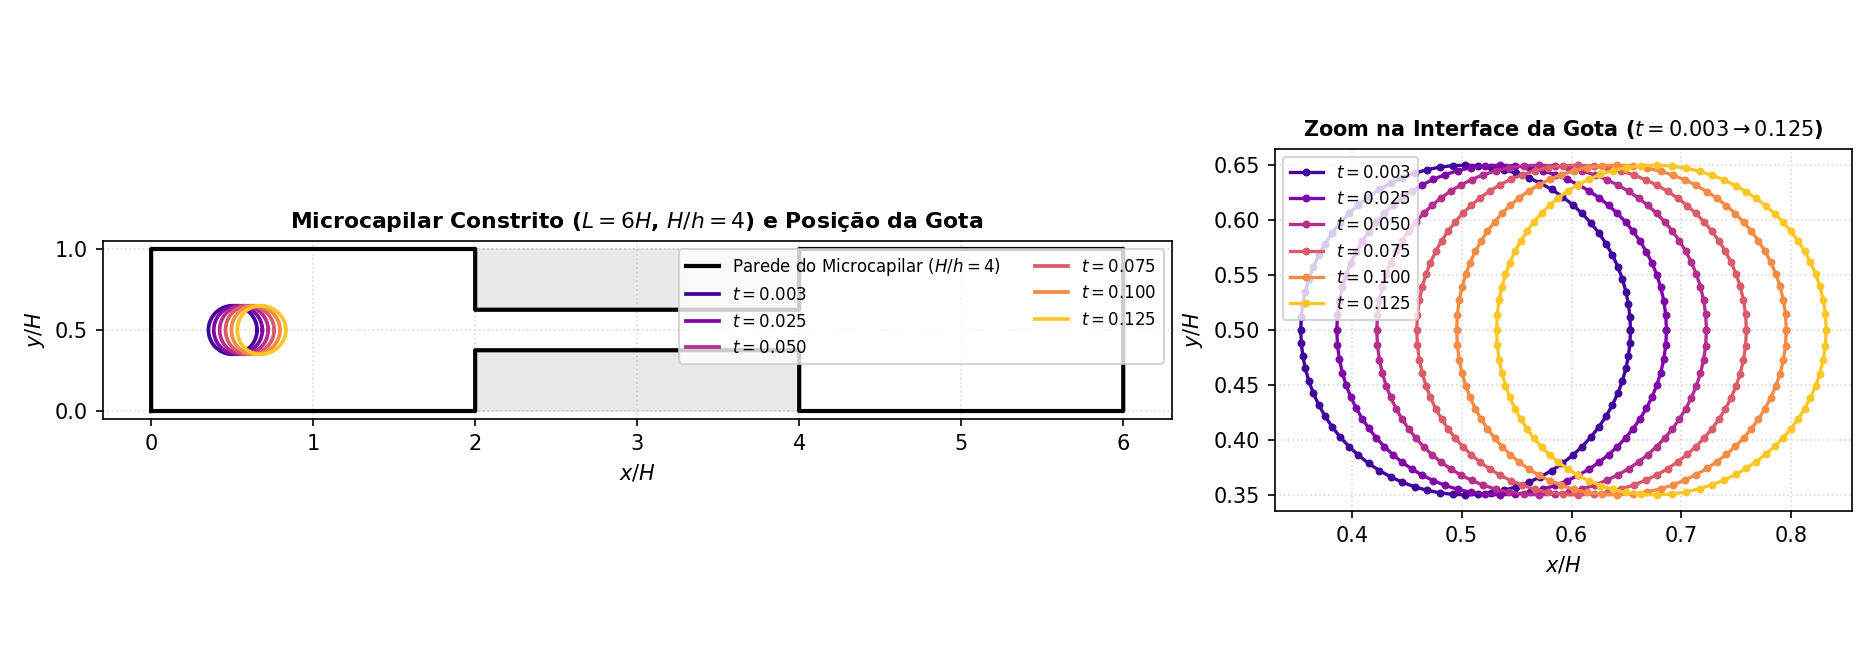


=== Figura 2 — Evolução Temporal da Diferença de Pressão Motriz Delta P(t) ===


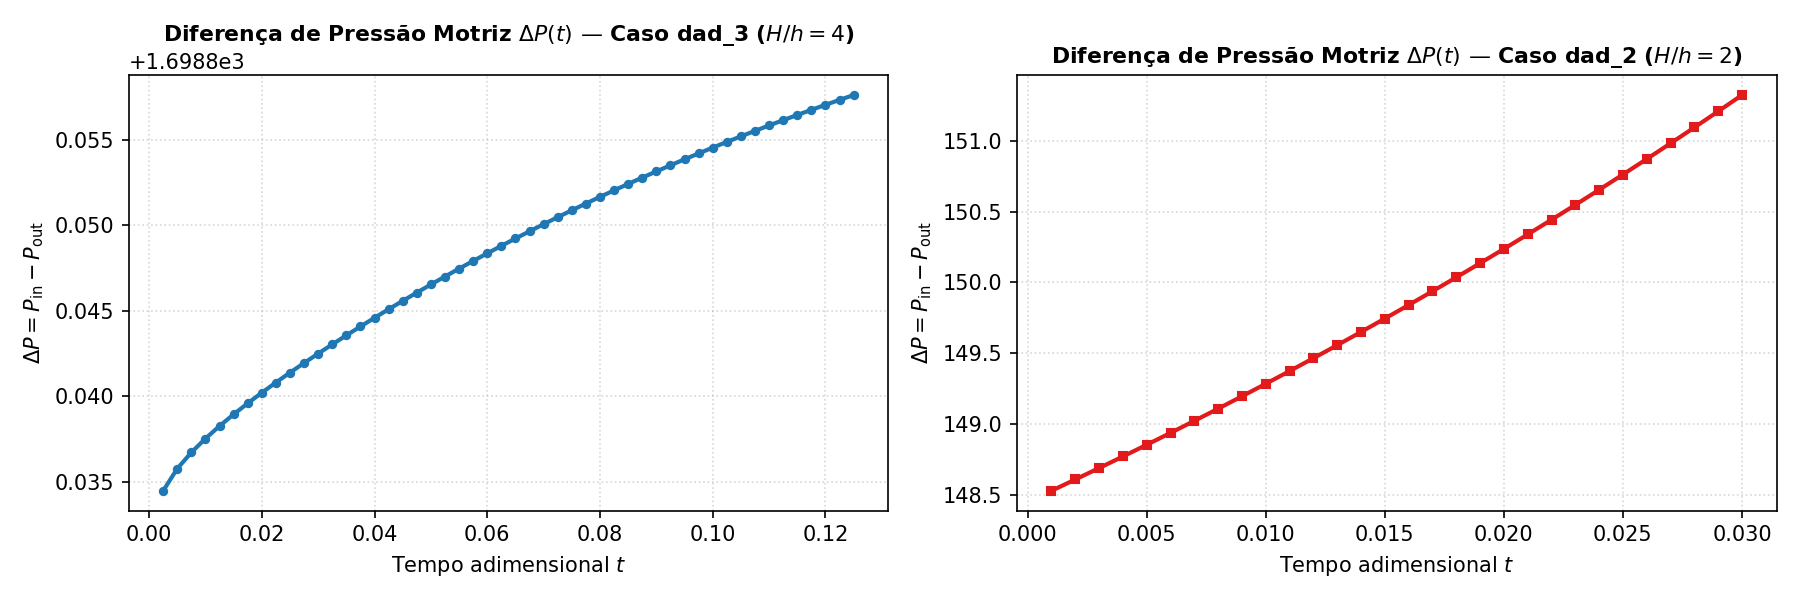


=== Figura 3 — Conservação de Vazão na Saída e Conservação da Área da Gota ===


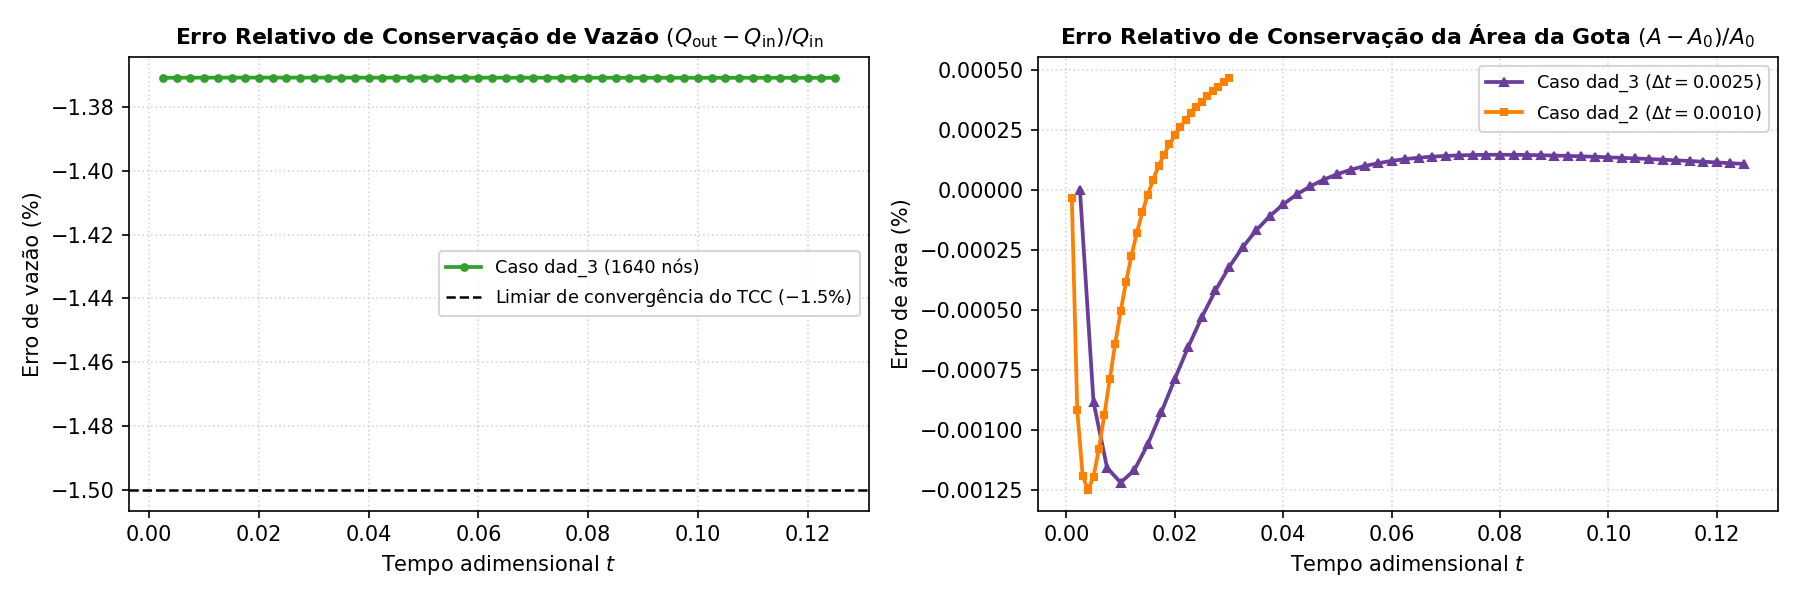


=== Figura 4 — Painel Resumo Integrado 2x2 (Stokes Drop BEM 2D) ===


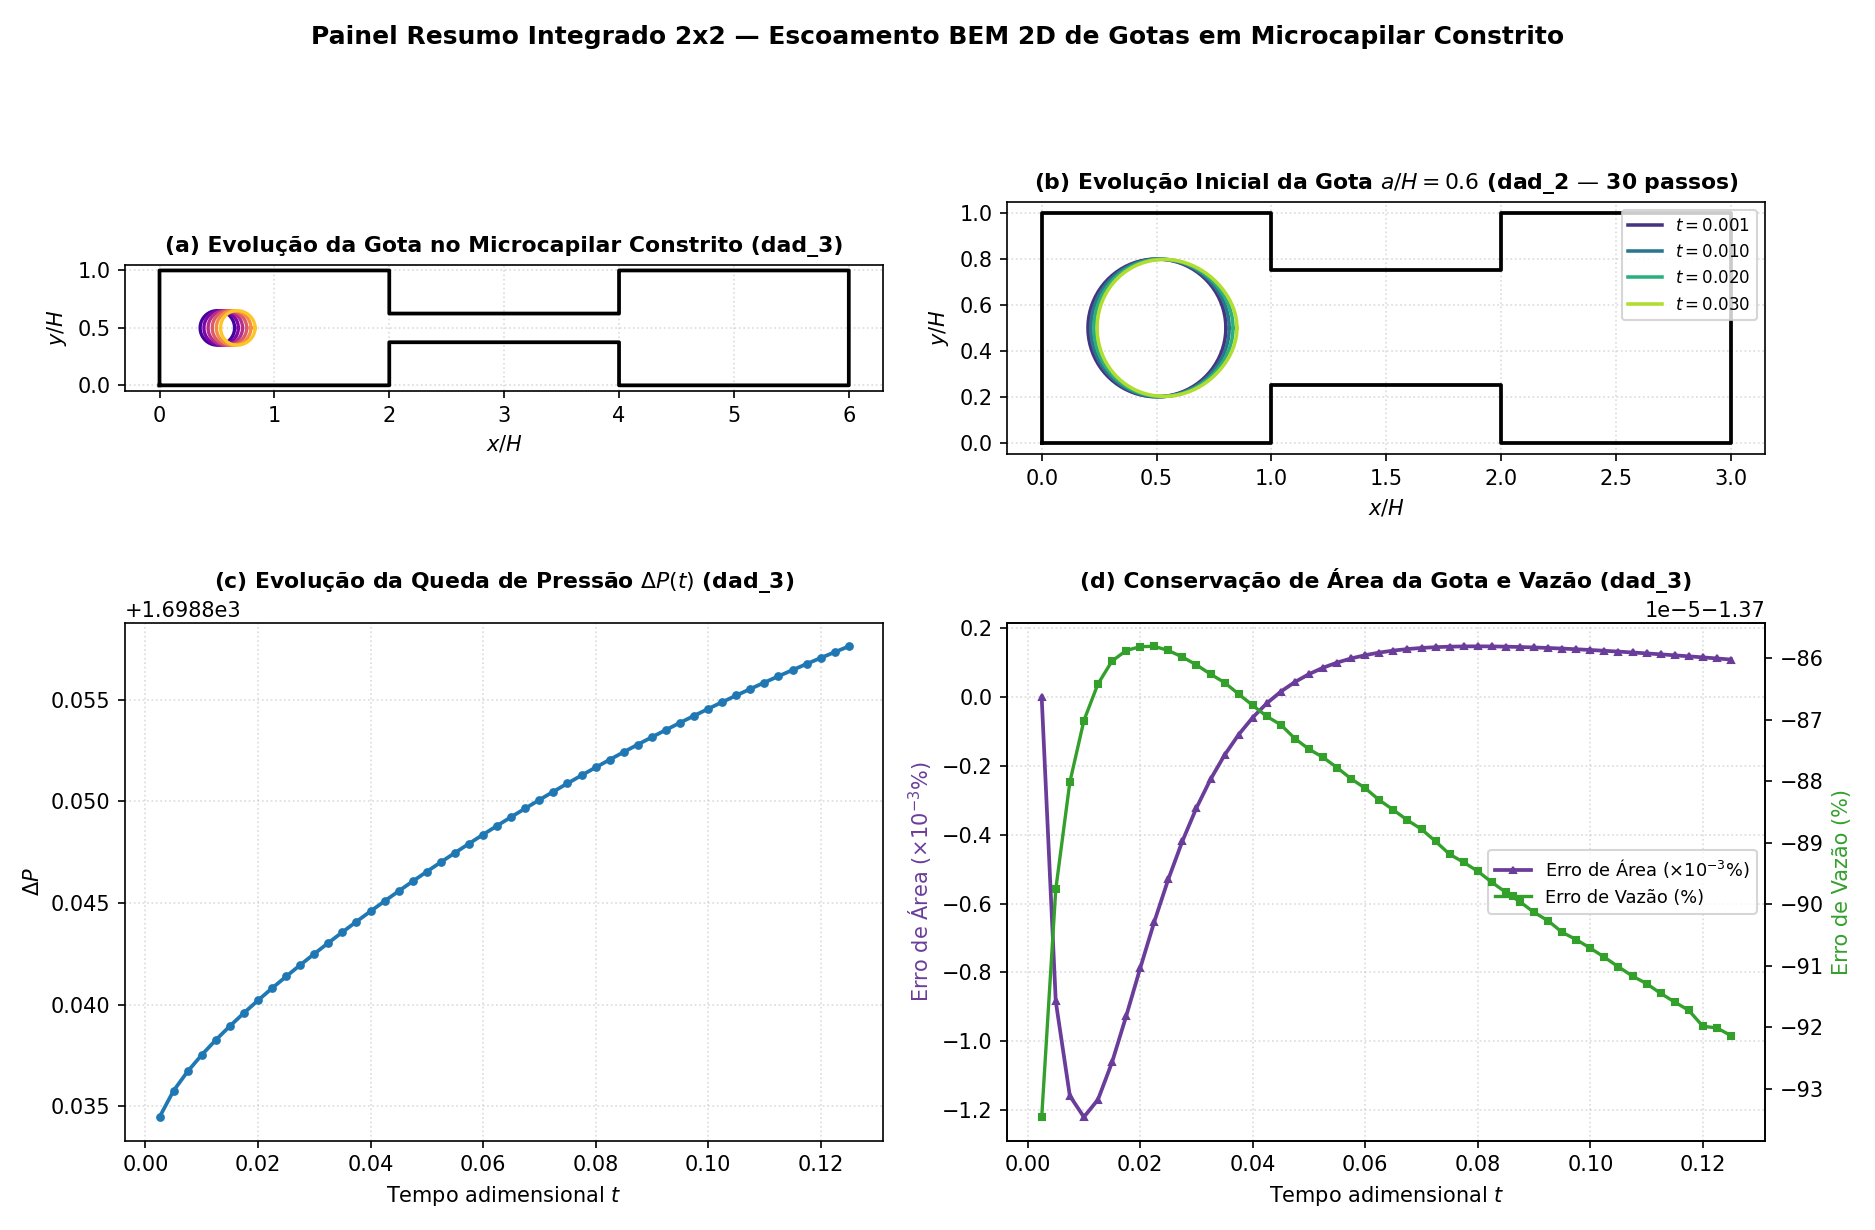

In [9]:
wall_d3 = np.loadtxt(PROC_DIR / "wall_contour.plt")
drop_files_d3 = sorted(PROC_DIR.glob("drop_t=*.plt"), key=lambda p: int(p.stem.split("=")[1]))
wall_d2 = np.loadtxt(RESULTS_DIR / "wall_contour.plt")
drop_files_d2 = sorted(RESULTS_DIR.glob("drop_t=*.plt"), key=lambda p: int(p.stem.split("=")[1]))

n_wall_d3 = mesh_dad3["drop_nodes"][0, 1]
wall_xy_d3 = wall_d3[:n_wall_d3]
n_wall_d2 = mesh_dad2["drop_nodes"][0, 1]
wall_xy_d2 = wall_d2[:n_wall_d2]
cmap = plt.cm.plasma(np.linspace(0.1, 0.88, len(drop_files_d3)))
cmap2 = plt.cm.viridis(np.linspace(0.15, 0.88, len(drop_files_d2)))

# 1) Figura 1: Canal constrito e evolução da gota
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.4), dpi=150, gridspec_kw={"width_ratios": [1.85, 1.0]})
ax1.plot(wall_xy_d3[:, 0], wall_xy_d3[:, 1], "k-", lw=2.0, label="Parede do Microcapilar ($H/h = 4$)")
ax1.fill_between([2.0, 4.0], [0.0, 0.0], [0.375, 0.375], color="#e0e0e0", alpha=0.7)
ax1.fill_between([2.0, 4.0], [0.625, 0.625], [1.0, 1.0], color="#e0e0e0", alpha=0.7)
for c, df in zip(cmap, drop_files_d3):
    t_ms = int(df.stem.split("=")[1])
    dxy = np.loadtxt(df)
    lbl = f"$t = {t_ms/1000:.3f}$"
    ax1.plot(dxy[:, 0], dxy[:, 1], "-", color=c, lw=1.8, label=lbl)
    ax2.plot(dxy[:, 0], dxy[:, 1], "-o", color=c, lw=1.6, ms=2.8, label=lbl)
ax1.set_title("Microcapilar Constrito ($L=6H$, $H/h=4$) e Posição da Gota", fontsize=10.5, fontweight="bold")
ax1.set_xlabel("$x / H$"); ax1.set_ylabel("$y / H$"); ax1.set_aspect("equal", adjustable="box")
ax1.grid(True, linestyle=":", alpha=0.45); ax1.legend(loc="upper right", fontsize=8, ncol=2)
ax2.set_title("Zoom na Interface da Gota ($t = 0.003 \\to 0.125$)", fontsize=10, fontweight="bold")
ax2.set_xlabel("$x / H$"); ax2.set_ylabel("$y / H$"); ax2.set_aspect("equal", adjustable="box")
ax2.grid(True, linestyle=":", alpha=0.45); ax2.legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(EXAMPLES_DIR / "fig1_evolucao_gota_canal.png", dpi=150); plt.close(fig)

# 2) Figura 2: Pressão motriz Delta P(t)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.0, 4.0), dpi=150)
ax1.plot(press_d3[:, 0], press_d3[:, 1], "-o", color="#1f78b4", lw=2.0, ms=3.5)
ax1.set_title("Diferença de Pressão Motriz $\\Delta P(t)$ — Caso dad_3 ($H/h=4$)", fontsize=10.5, fontweight="bold")
ax1.set_xlabel("Tempo adimensional $t$"); ax1.set_ylabel("$\\Delta P = P_{\\mathrm{in}} - P_{\\mathrm{out}}$"); ax1.grid(True, linestyle=":", alpha=0.5)
ax2.plot(press_d2[:, 0], press_d2[:, 1], "-s", color="#e31a1c", lw=2.0, ms=3.5)
ax2.set_title("Diferença de Pressão Motriz $\\Delta P(t)$ — Caso dad_2 ($H/h=2$)", fontsize=10.5, fontweight="bold")
ax2.set_xlabel("Tempo adimensional $t$"); ax2.set_ylabel("$\\Delta P = P_{\\mathrm{in}} - P_{\\mathrm{out}}$"); ax2.grid(True, linestyle=":", alpha=0.5)
fig.tight_layout(); fig.savefig(EXAMPLES_DIR / "fig2_pressao_motriz.png", dpi=150); plt.close(fig)

# 3) Figura 3: Erros de conservação de vazão e área
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.0, 4.0), dpi=150)
ax1.plot(flow_d3[:, 0], flow_d3[:, 1], "-o", color="#33a02c", lw=1.8, ms=3.2, label="Caso dad_3 (1640 nós)")
ax1.axhline(-1.5, color="k", linestyle="--", lw=1.2, label="Limiar de convergência do TCC ($-1.5\\%$)")
ax1.set_title("Erro Relativo de Conservação de Vazão $(Q_{\\mathrm{out}}-Q_{\\mathrm{in}})/Q_{\\mathrm{in}}$", fontsize=10.5, fontweight="bold")
ax1.set_xlabel("Tempo adimensional $t$"); ax1.set_ylabel("Erro de vazão (%)"); ax1.grid(True, linestyle=":", alpha=0.5); ax1.legend(fontsize=8.5)
ax2.plot(area_d3[:, 0], area_d3[:, 1], "-^", color="#6a3d9a", lw=1.8, ms=3.5, label="Caso dad_3 ($\\Delta t = 0.0025$)")
ax2.plot(area_d2[:, 0], area_d2[:, 1], "-s", color="#ff7f00", lw=1.8, ms=3.2, label="Caso dad_2 ($\\Delta t = 0.0010$)")
ax2.set_title("Erro Relativo de Conservação da Área da Gota $(A - A_0)/A_0$", fontsize=10.5, fontweight="bold")
ax2.set_xlabel("Tempo adimensional $t$"); ax2.set_ylabel("Erro de área (%)"); ax2.grid(True, linestyle=":", alpha=0.5); ax2.legend(fontsize=8.5)
fig.tight_layout(); fig.savefig(EXAMPLES_DIR / "fig3_erros_vazao_area.png", dpi=150); plt.close(fig)

# 4) Figura 4: Dashboard 2x2
fig, axs = plt.subplots(2, 2, figsize=(12.5, 8.2), dpi=150)
axs[0, 0].plot(wall_xy_d3[:, 0], wall_xy_d3[:, 1], "k-", lw=1.8)
for c, df in zip(cmap, drop_files_d3):
    dxy = np.loadtxt(df)
    axs[0, 0].plot(dxy[:, 0], dxy[:, 1], "-", color=c, lw=1.6)
axs[0, 0].set_title("(a) Evolução da Gota no Microcapilar Constrito (dad_3)", fontsize=10.5, fontweight="bold")
axs[0, 0].set_xlabel("$x / H$"); axs[0, 0].set_ylabel("$y / H$"); axs[0, 0].set_aspect("equal", adjustable="box"); axs[0, 0].grid(True, linestyle=":", alpha=0.45)

axs[0, 1].plot(wall_xy_d2[:, 0], wall_xy_d2[:, 1], "k-", lw=1.8)
for c, df in zip(cmap2, drop_files_d2):
    t_ms = int(df.stem.split("=")[1])
    dxy = np.loadtxt(df)
    axs[0, 1].plot(dxy[:, 0], dxy[:, 1], "-", color=c, lw=1.7, label=f"$t={t_ms/1000:.3f}$")
axs[0, 1].set_title("(b) Evolução Inicial da Gota $a/H=0.6$ (dad_2 — 30 passos)", fontsize=10.5, fontweight="bold")
axs[0, 1].set_xlabel("$x / H$"); axs[0, 1].set_ylabel("$y / H$"); axs[0, 1].set_aspect("equal", adjustable="box"); axs[0, 1].grid(True, linestyle=":", alpha=0.45); axs[0, 1].legend(loc="upper right", fontsize=8)

axs[1, 0].plot(press_d3[:, 0], press_d3[:, 1], "-o", color="#1f78b4", lw=1.8, ms=3.2)
axs[1, 0].set_title("(c) Evolução da Queda de Pressão $\\Delta P(t)$ (dad_3)", fontsize=10.5, fontweight="bold")
axs[1, 0].set_xlabel("Tempo adimensional $t$"); axs[1, 0].set_ylabel("$\\Delta P$"); axs[1, 0].grid(True, linestyle=":", alpha=0.45)

ax_r = axs[1, 1].twinx()
l1 = axs[1, 1].plot(area_d3[:, 0], area_d3[:, 1] * 1e3, "-^", color="#6a3d9a", lw=1.8, ms=3.2, label="Erro de Área ($\\times 10^{-3}\\%$)")
l2 = ax_r.plot(flow_d3[:, 0], flow_d3[:, 1], "-s", color="#33a02c", lw=1.6, ms=3.0, label="Erro de Vazão (%)")
axs[1, 1].set_title("(d) Conservação de Área da Gota e Vazão (dad_3)", fontsize=10.5, fontweight="bold")
axs[1, 1].set_xlabel("Tempo adimensional $t$"); axs[1, 1].set_ylabel("Erro de Área ($\\times 10^{-3}\\%$)", color="#6a3d9a")
ax_r.set_ylabel("Erro de Vazão (%)", color="#33a02c"); axs[1, 1].grid(True, linestyle=":", alpha=0.45)
lines_all = l1 + l2; axs[1, 1].legend(lines_all, [l.get_label() for l in lines_all], loc="center right", fontsize=8.5)
fig.suptitle("Painel Resumo Integrado 2x2 — Escoamento BEM 2D de Gotas em Microcapilar Constrito", fontsize=12, fontweight="bold")
fig.tight_layout(); fig.savefig(EXAMPLES_DIR / "fig4_dashboard_resumo.png", dpi=150); plt.close(fig)

figs_post = [
    ("Figura 1 — Microcapilar Constrito e Evolução dos Perfis da Gota (dad_3)", "fig1_evolucao_gota_canal.png"),
    ("Figura 2 — Evolução Temporal da Diferença de Pressão Motriz Delta P(t)", "fig2_pressao_motriz.png"),
    ("Figura 3 — Conservação de Vazão na Saída e Conservação da Área da Gota", "fig3_erros_vazao_area.png"),
    ("Figura 4 — Painel Resumo Integrado 2x2 (Stokes Drop BEM 2D)", "fig4_dashboard_resumo.png"),
]

for titulo, fname in figs_post:
    fpath = EXAMPLES_DIR / fname
    if fpath.exists():
        print(f"\n=== {titulo} ===")
        display(Image(filename=str(fpath), width=780))

## 9. Quadro-Resumo Comparativo: Protótipo MATLAB vs. Solver Fortran 90 e Benchmarks

A tabela abaixo resume as diferenças estruturais entre o protótipo preliminar em MATLAB (`FluidosDeStokes - 20160220/FluidoStokes.m`) e o framework final em Fortran 90 (`Create_Mesh_2D` + `Processor`), juntamente com as métricas de verificação obtidas:

| Aspecto / Métrica | Protótipo MATLAB (`FluidoStokes.m`) | Solver Fortran 90 (`Create_Mesh_2D` + `Processor`) | Referência TCC / Artigo IJMF (2018) |
|---|---|---|---|
| **Geometria do Canal** | Canal plano reto ($20 \times 10$, `dad_2.m`) | Canal reto (`dad_1`) e microcapilares constritos (`dad_2`, `dad_3`) | Microcapilar constrito $L_u/H=L_d/H=1$, $L_c/H=5$, $H/h=4$ |
| **Condição na Entrada** | Velocidade uniforme ($u_x = 1, u_y = 0$) | Perfil parabólico de Poiseuille desenvolvido (`bc = 2`) | Perfil parabólico de Poiseuille com vazão constante $Q$ |
| **Integração Singular** | Gauss-Legendre padrão | Subtração de singularidade + Gauss Logarítmica ($N_{\text{pgs}} = 10$) | Decomposição regular + logarítmica singular |
| **Solver Linear** | Direto (`matA \ b`) | Gradientes Biconjugados (`Conj_grad`, BiCG, `Tol = 1e-8`, `real*8`) | Solver iterativo BiCG para matriz cheia não-simétrica |
| **Avanço Temporal** | Euler explícito de 1ª ordem (`evoluca2.m`, $\Delta t = 0,5$) | Preditor-corretor de 2ª ordem (`evolution_euler` + `evolution_euler_implicit`) | Euler explícito / preditor-corretor com $\Delta t \le 0,01$ |
| **Realocação de Nós** | Comentada (`rep_no1.m`, `rep_no2.m`) | Ativa: 2 passagens por passo (`nodes_relocation.f90`) | Algoritmo de Wrobel et al. (2009) |
| **Erro de Vazão $e_Q$** | Não avaliado | **`-1,371%`** (`dad_3`, 820 elementos) | **`~1,5%`** para fator de refinamento $N_e = 7$ (TCC, Fig. 4.3) |
| **Erro de Área $|e_A|$** | Não avaliado | **`0,00011%`** final / **`0,00122%`** máx (`dad_3`, $\Delta t = 0,0025$) | **`< 0,5%`** ao longo de toda a simulação (TCC, Cap. 4) |

---

## 10. Guia Prático para o Aluno: Como Criar e Simular Seu Próprio Caso

Para modelar uma nova geometria de canal ou alterar os parâmetros adimensionais ($\lambda, \text{Ca}, a/H, \Delta t$):
1. **Crie ou edite um arquivo `<meu_caso>.txt` na pasta `Create_Mesh_2D/`**:
   - Defina `npts  nseg  ndrop` na 2ª linha e `dt  max_pos  max_it` na 5ª linha;
   - Liste as coordenadas dos pontos do contorno externo no sentido anti-horário;
   - Conecte os pontos nos segmentos indicando `0.0` (parede), `-1.0` (entrada) ou `-2.0` (saída);
   - Aplique `2.0  1.0  0.0  0.0` no segmento de entrada para perfil parabólico com velocidade média unitária e `1.0  0.0  1.0  0.0` na saída para tração livre;
   - Defina o número de elementos de cada segmento, `drop_nele`, $\lambda$, $\text{Ca}$ e `(id, x_c, y_c, R)` da gota.
2. **Grave o nome do caso (sem `.txt`) em `Create_Mesh_2D/file_name.dat` e gere a malha**:
   ```powershell
   Set-Content .\Create_Mesh_2D\file_name.dat "meu_caso"
   cd .\Create_Mesh_2D
   "`n" | .\Mesh.exe
   ```
3. **Copie `output.txt` para `Processor/` e execute o solver**:
   ```powershell
   Copy-Item .\Create_Mesh_2D\output.txt .\Processor\output.txt
   cd .\Processor
   .\Gota.exe
   ```
4. **Pós-processe os arquivos `.plt`**:
   - Reexecute as células das **Seções 7 e 8** deste notebook apontando para o diretório onde `Gota.exe` foi executado para visualizar a evolução da interface `drop_t=*.plt`, a queda de pressão $\Delta P(t)$ (`pressure.plt`) e os erros de conservação (`flow_error.plt` e `area_error.plt`).